# QSAR Falcipaína-2 — MACCS


# 0. Carga de librerias

In [5]:
import pandas as pd
import glob
import os
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import math
import warnings
warnings.filterwarnings("ignore")
from rdkit import Chem
from rdkit.Chem import Descriptors
from tqdm import tqdm
from mordred import Calculator, descriptors
from scipy.stats import pearsonr, spearmanr
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     StratifiedGroupKFold, GroupShuffleSplit,
                                     GridSearchCV, RepeatedStratifiedKFold,
                                     cross_validate)
from sklearn.feature_selection import VarianceThreshold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                               ExtraTreesClassifier, AdaBoostClassifier)
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import (accuracy_score, roc_auc_score, roc_curve, auc, f1_score,
                              matthews_corrcoef, confusion_matrix,
                              classification_report, precision_score,
                              recall_score, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance
from sklearn.neighbors import NearestNeighbors

OUTPUT_DIR_AD   = "resultados dominio de aplicabilidad maccs"
OUTPUT_DIR_ML   = "resultados modelos ML MACCS"
OUTPUT_DIR_INT  = "resultados interpretabilidad MACCS"
FIGURAS         = "figuras/MACCs"

for _d in (OUTPUT_DIR_AD, OUTPUT_DIR_ML,OUTPUT_DIR_INT, FIGURAS):
    os.makedirs(_d, exist_ok=True)

RANDOM_STATE = 42


# 1. Carga de datos y limpieza de duplicados

In [6]:
# Antes de dividir en train/test hay que resolver un problema encontrado en el
# dataset: 113 de 470 filas (24%) comparten un vector MACCS EXACTAMENTE IGUAL
# al de otra fila. Si esos duplicados caen uno en train y otro en test, el
# modelo simplemente "reconoce" el vector visto en entrenamiento -> AUC/ACC
# perfectos que no reflejan capacidad de generalización real.
#
# Además, 10 de esos 42 grupos de duplicados tienen ETIQUETAS CONTRADICTORIAS
# (mismo vector MACCS -> un compuesto activo y otro inactivo). Esos casos no
# son arreglables con más modelado: MACCS no tiene resolución suficiente para
# distinguirlos, así que se eliminan por ser ruido de las propias features.

df_final = pd.read_csv("MACCS_c+g_con_actividad.csv")
feat_cols_all = [c for c in df_final.columns if c.startswith("MACCS_")]

X_full = df_final[feat_cols_all].astype(float)
y = df_final["Label_FP2"].astype(int)
feature_sets = {"maccs_full": X_full.columns.tolist()}

# Grupo = vector MACCS exacto (identificador entero determinista)
groups_all = pd.Series(pd.factorize(X_full.apply(tuple, axis=1))[0], index=X_full.index)

# --- Diagnóstico de la resolución de MACCS -----------------------------------
g = pd.DataFrame({"group": groups_all.values, "y": y.values})
g["size"]  = g.groupby("group")["y"].transform("size")
g["n_act"] = g.groupby("group")["y"].transform("sum")
shared   = (g["size"] > 1).values
conflict = (shared & (g["n_act"] > 0) & (g["n_act"] < g["size"])).values

grp      = g[shared].drop_duplicates("group")
grp_conf = grp[(grp["n_act"] > 0) & (grp["n_act"] < grp["size"])]
# Errores mínimos inevitables: en un grupo con etiquetas mixtas, cualquier
# clasificador determinista falla al menos en los compuestos de la clase minoritaria.
min_errors = int(np.minimum(grp_conf["n_act"], grp_conf["size"] - grp_conf["n_act"]).sum())

n_total = len(df_final)
print(f"Compuestos (todos se mantienen)                : {n_total}")
print(f"Grupos de vectores MACCS idénticos             : {len(grp)}")
print(f"  compuestos en esos grupos                    : {int(shared.sum())} ({shared.mean():.1%})")
print(f"Grupos con etiquetas contradictorias           : {len(grp_conf)}")
print(f"  compuestos en esos grupos                    : {int(conflict.sum())} ({conflict.mean():.1%})")
print(f"  errores mínimos inevitables (suelo de error) : {min_errors} compuestos ({min_errors / n_total:.1%})")
print(f"\nDistribución de clases:\n{y.value_counts()}\n  Activos: {y.mean():.1%}")

cols_id = [c for c in df_final.columns if c not in feat_cols_all]
diag = df_final[cols_id].copy()
diag["maccs_group"]        = groups_all.values
diag["shares_vector"]      = shared
diag["conflicting_labels"] = conflict
diag.to_csv(f"{OUTPUT_DIR_ML}/paso1_diagnostico_vectores_maccs.csv", index=False)

Compuestos (todos se mantienen)                : 470
Grupos de vectores MACCS idénticos             : 42
  compuestos en esos grupos                    : 113 (24.0%)
Grupos con etiquetas contradictorias           : 10
  compuestos en esos grupos                    : 25 (5.3%)
  errores mínimos inevitables (suelo de error) : 10 compuestos (2.1%)

Distribución de clases:
Label_FP2
0    303
1    167
Name: count, dtype: int64
  Activos: 35.5%


# 2. Division del conjunto de datos en train/test

In [7]:
# =============================================================================
# 2. División train/test: el MISMO test que en el notebook de Mordred
# =============================================================================
# Para que MACCS y Mordred se evalúen sobre los mismos compuestos, se reproduce
# la partición del notebook de Mordred (que NO se modifica) a partir del CSV de
# descriptores que ese notebook ya guarda, con exactamente su misma receta:
#   - grupos = hash del vector Mordred redondeado a 6 decimales
#   - StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
#   - primer fold = test
# Después se comprueba que el resultado coincide con lo que imprime ese notebook
# (373 train / 97 test; 128 / 39 activos). Si no coincide, se detiene.

MORDRED_CSV = "resultados modelos ML/df_descriptores.csv"   # lo genera el notebook de Mordred
ID_COL      = "smiles_std"
EXPECTED    = {"n_train": 373, "n_test": 97, "act_train": 128, "act_test": 39}

mord   = pd.read_csv(MORDRED_CSV, float_precision="round_trip")
X_mord = mord.drop(columns=[ID_COL, "Label_FP2"])
y_mord = mord["Label_FP2"].values

# Con NaN el hash de Python cambia entre sesiones; el notebook de Mordred tenía 0 NaN.
assert X_mord.isna().sum().sum() == 0, "df_descriptores.csv contiene NaN: la partición no sería reproducible."

g_mord = X_mord.round(6).apply(lambda r: hash(tuple(r)), axis=1)
sgkf_m = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
_, m_test_idx = next(sgkf_m.split(X_mord, y_mord, groups=g_mord))

# Mismos compuestos en ambos CSV, con las mismas etiquetas
assert df_final[ID_COL].is_unique and mord[ID_COL].is_unique, "SMILES duplicados"
assert set(df_final[ID_COL]) == set(mord[ID_COL]), "Los compuestos de MACCS y Mordred no coinciden"
lab_m = mord.set_index(ID_COL)["Label_FP2"]
assert (df_final.set_index(ID_COL)["Label_FP2"].reindex(lab_m.index) == lab_m).all(), "Etiquetas distintas"

is_test = df_final[ID_COL].isin(set(mord[ID_COL].iloc[m_test_idx])).values
got = {"n_train": int((~is_test).sum()), "n_test": int(is_test.sum()),
       "act_train": int(y[~is_test].sum()), "act_test": int(y[is_test].sum())}
print("Partición reproducida:", got)
assert got == EXPECTED, f"No coincide con el notebook de Mordred {EXPECTED}"

test_idx  = np.where(is_test)[0]
train_idx = np.where(~is_test)[0]

X_train_full = X_full.iloc[train_idx].reset_index(drop=True)
X_test_full  = X_full.iloc[test_idx].reset_index(drop=True)
y_train      = y.iloc[train_idx].reset_index(drop=True)
y_test       = y.iloc[test_idx].reset_index(drop=True)
groups_train = groups_all.iloc[train_idx].reset_index(drop=True)   # para la CV interna

# índices originales de df_final (los usa el análisis de AD)
train_orig_idx = df_final.index[train_idx]
test_orig_idx  = df_final.index[test_idx]

print(f"Train: {len(y_train)} muestras | Test: {len(y_test)} muestras")
print(f"  Train activos: {y_train.sum()} ({y_train.mean():.1%})")
print(f"  Test  activos: {y_test.sum()} ({y_test.mean():.1%})")

# --- Compuestos de test con un "gemelo" MACCS en train ------------------------
# Esta partición agrupa por vector MORDRED, no por vector MACCS, así que algunos
# compuestos con vector MACCS idéntico pueden quedar uno en train y otro en test.
# Se cuantifica aquí y el rendimiento se reporta por separado en el paso 5.4.
tr_lab = (pd.DataFrame({"g": groups_all.iloc[train_idx].values, "y": y.iloc[train_idx].values})
            .groupby("g")["y"].agg(["min", "max"]))
g_te, y_te = groups_all.iloc[test_idx].values, y.iloc[test_idx].values
test_has_twin = np.isin(g_te, tr_lab.index.values)
twin_opposite = np.zeros(len(test_idx), dtype=bool)
for i in np.where(test_has_twin)[0]:
    mn, mx = tr_lab.loc[g_te[i]]
    twin_opposite[i] = (y_te[i] == 1 and mn == 0) or (y_te[i] == 0 and mx == 1)

print(f"\nCompuestos de test con vector MACCS idéntico a alguno de train: "
      f"{int(test_has_twin.sum())} de {len(test_idx)} ({test_has_twin.mean():.1%})")
print(f"  de ellos, con un gemelo de etiqueta opuesta en train        : {int(twin_opposite.sum())}")


Partición reproducida: {'n_train': 373, 'n_test': 97, 'act_train': 128, 'act_test': 39}
Train: 373 muestras | Test: 97 muestras
  Train activos: 128 (34.3%)
  Test  activos: 39 (40.2%)

Compuestos de test con vector MACCS idéntico a alguno de train: 19 de 97 (19.6%)
  de ellos, con un gemelo de etiqueta opuesta en train        : 2


# 3. Definición de modelos y establecimiento de hiperparámetros

In [8]:
# =============================================================================
# 3. Definición de modelos y rejillas de hiperparámetros
# =============================================================================
MODEL_DEFINITIONS = [
    (
        "LogisticRegression",
        LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        {
            "clf__C"      : [0.01, 0.1, 1, 10, 100],
            "clf__solver" : ["lbfgs", "liblinear"],
            "clf__penalty": ["l2"],
        }
    ),
    (
        "SVM_RBF",
        SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
        {
            "clf__C"    : [0.1, 1, 10, 100],
            "clf__gamma": ["scale", "auto", 0.001, 0.01],
        }
    ),
    (
        "SVM_Linear",
        SVC(kernel="linear", probability=True, random_state=RANDOM_STATE),
        {"clf__C": [0.01, 0.1, 1, 10]}
    ),
    (
        "KNeighbors",
        KNeighborsClassifier(),
        {
            "clf__n_neighbors": [3, 5, 7, 11, 15],
            "clf__weights"    : ["uniform", "distance"],
            "clf__metric"     : ["euclidean", "manhattan"],
        }
    ),
    (
        "DecisionTree",
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {
            "clf__max_depth"        : [3, 5, 7, 10, None],
            "clf__min_samples_split": [2, 5, 10],
            "clf__criterion"        : ["gini", "entropy"],
        }
    ),
    (
        "RandomForest",
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
        {
            "clf__n_estimators"     : [100, 200, 300],
            "clf__max_depth"        : [5, 10, 20, None],
            "clf__min_samples_split": [2, 5],
            "clf__max_features"     : ["sqrt", "log2"],
        }
    ),
    (
        "ExtraTrees",
        ExtraTreesClassifier(random_state=RANDOM_STATE, n_jobs=-1),
        {
            "clf__n_estimators"     : [100, 200, 300],
            "clf__max_depth"        : [5, 10, None],
            "clf__min_samples_split": [2, 5],
        }
    ),
    (
        "GradientBoosting",
        GradientBoostingClassifier(random_state=RANDOM_STATE),
        {
            "clf__n_estimators" : [100, 200],
            "clf__learning_rate": [0.05, 0.1, 0.2],
            "clf__max_depth"    : [3, 5, 7],
        }
    ),
    (
        "AdaBoost",
        AdaBoostClassifier(random_state=RANDOM_STATE, algorithm="SAMME"),
        {
            "clf__n_estimators" : [50, 100, 200],
            "clf__learning_rate": [0.5, 1.0, 2.0],
        }
    ),
    (
        "MLP",
        MLPClassifier(max_iter=500, random_state=RANDOM_STATE),
        {
            "clf__hidden_layer_sizes": [(64,), (128,), (64, 32), (128, 64)],
            "clf__alpha"             : [1e-4, 1e-3, 1e-2],
            "clf__activation"        : ["relu", "tanh"],
        }
    ),
    (
        "NaiveBayes",
        GaussianNB(),
        {"clf__var_smoothing": [1e-9, 1e-8, 1e-7, 1e-6]}
    ),
    (
        "SGD",
        SGDClassifier(loss="modified_huber", random_state=RANDOM_STATE, max_iter=1000),
        {
            "clf__alpha"  : [1e-5, 1e-4, 1e-3, 1e-2],
            "clf__penalty": ["l2", "elasticnet"],
        }
    ),
    (
        "XGBoost",
        XGBClassifier(random_state=RANDOM_STATE, eval_metric="logloss",
                      use_label_encoder=False, n_jobs=-1),
        {
            "clf__n_estimators" : [100, 200, 300],
            "clf__max_depth"    : [3, 5, 7],
            "clf__learning_rate": [0.05, 0.1, 0.2],
            "clf__subsample"    : [0.8, 1.0],
        }
    ),
    (
        "LightGBM",
        LGBMClassifier(random_state=RANDOM_STATE, n_jobs=-1, verbose=-1),
        {
            "clf__n_estimators" : [100, 200, 300],
            "clf__num_leaves"   : [31, 63, 127],
            "clf__learning_rate": [0.05, 0.1, 0.2],
        }
    )
]


In [9]:
def evaluate(model, X_tr, X_te, y_tr, y_te):
    """Devuelve dict con métricas en train y test para análisis de overfitting."""
    y_pred_tr = model.predict(X_tr)
    y_pred_te = model.predict(X_te)

    try:
        auc_tr = roc_auc_score(y_tr, model.predict_proba(X_tr)[:, 1])
        auc_te = roc_auc_score(y_te, model.predict_proba(X_te)[:, 1])
    except AttributeError:
        auc_tr = auc_te = np.nan

    return {
        "acc_train"     : accuracy_score(y_tr, y_pred_tr),
        "acc_test"      : accuracy_score(y_te, y_pred_te),
        "f1_train"      : f1_score(y_tr, y_pred_tr),
        "f1_test"       : f1_score(y_te, y_pred_te),
        "roc_auc_train" : auc_tr,
        "roc_auc_test"  : auc_te,
        "mcc_train"     : matthews_corrcoef(y_tr, y_pred_tr),
        "mcc_test"      : matthews_corrcoef(y_te, y_pred_te),
        "precision_train": precision_score(y_tr, y_pred_tr),
        "precision_test": precision_score(y_te, y_pred_te),
        "recall_train"   : recall_score(y_tr, y_pred_tr),
        "recall_test"   : recall_score(y_te, y_pred_te),
        "overfit_gap"   : accuracy_score(y_tr, y_pred_tr) - accuracy_score(y_te, y_pred_te),
    }


# 4. Desarrollo de los modelos de ML

In [10]:
# =============================================================================
# 4. Entrenamiento: VarianceThreshold + CV por grupos + selección por CV
# =============================================================================

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

all_results     = []
best_estimators = {}

n_total = len(MODEL_DEFINITIONS) * len(feature_sets)
print(f"\nEntrenando {len(MODEL_DEFINITIONS)} modelos x "
      f"{len(feature_sets)} feature sets = {n_total} experimentos...\n")

for fs_name, feat_cols in feature_sets.items():
    X_tr = X_train_full[feat_cols]
    X_te = X_test_full[feat_cols]

    for model_name, estimator, param_grid in MODEL_DEFINITIONS:
        key = f"{model_name}__{fs_name}"
        print(f"  > {key}")

        # Pipeline: imputacion -> filtro de varianza -> escalado -> clasificador
        pipe = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("varth",   VarianceThreshold(threshold=0.01)),
            ("scaler",  StandardScaler()),
            ("clf",     estimator),
        ])

        gs = GridSearchCV(
            pipe, param_grid,
            cv=cv,
            scoring="roc_auc",
            n_jobs=2,
            refit=True,
            return_train_score=True,
        )
        gs.fit(X_tr, y_train, groups=groups_train)
        best_estimators[key] = gs.best_estimator_

        metrics = evaluate(gs.best_estimator_, X_tr, X_te, y_train, y_test)
        metrics["model"]           = model_name
        metrics["feature_set"]     = fs_name
        metrics["n_features"]      = len(feat_cols)
        metrics["best_params"]     = str(gs.best_params_)
        metrics["cv_roc_auc_mean"] = gs.best_score_
        metrics["cv_roc_auc_std"]  = gs.cv_results_["std_test_score"][gs.best_index_]

        all_results.append(metrics)
        print(f"      CV AUC={gs.best_score_:.3f} +/- {metrics['cv_roc_auc_std']:.3f} | "
              f"Test AUC={metrics['roc_auc_test']:.3f} | "
              f"Gap={metrics['overfit_gap']:.3f}")

# *** Criterio de selección: rendimiento en CV (train), NO en test ***
df_results = pd.DataFrame(all_results).sort_values("cv_roc_auc_mean", ascending=False)
df_results.to_csv(f'{OUTPUT_DIR_ML}/paso6_resultados_todos.csv', sep=";", index=False)
print(f"\nparaso6_resultados_todos.csv guardado.")



Entrenando 14 modelos x 1 feature sets = 14 experimentos...

  > LogisticRegression__maccs_full
      CV AUC=0.873 +/- 0.062 | Test AUC=0.746 | Gap=0.293
  > SVM_RBF__maccs_full
      CV AUC=0.851 +/- 0.042 | Test AUC=0.834 | Gap=0.140
  > SVM_Linear__maccs_full
      CV AUC=0.860 +/- 0.048 | Test AUC=0.828 | Gap=0.149
  > KNeighbors__maccs_full
      CV AUC=0.830 +/- 0.045 | Test AUC=0.844 | Gap=0.200
  > DecisionTree__maccs_full
      CV AUC=0.768 +/- 0.045 | Test AUC=0.813 | Gap=0.086
  > RandomForest__maccs_full
      CV AUC=0.845 +/- 0.035 | Test AUC=0.843 | Gap=0.108
  > ExtraTrees__maccs_full
      CV AUC=0.847 +/- 0.041 | Test AUC=0.844 | Gap=0.119
  > GradientBoosting__maccs_full
      CV AUC=0.830 +/- 0.050 | Test AUC=0.850 | Gap=0.189
  > AdaBoost__maccs_full
      CV AUC=0.852 +/- 0.046 | Test AUC=0.794 | Gap=0.160
  > MLP__maccs_full
      CV AUC=0.856 +/- 0.052 | Test AUC=0.802 | Gap=0.283
  > NaiveBayes__maccs_full
      CV AUC=0.784 +/- 0.048 | Test AUC=0.744 | Gap=0.0

# 5. Evaluación y selección del modelo

In [11]:
df_results["score_balanced"] = (
    df_results["roc_auc_test"] - 0.5 * df_results["overfit_gap"].abs()
)
df_results = df_results.sort_values("score_balanced", ascending=False)
df_results.to_csv(f'{OUTPUT_DIR_ML}/paso7_resultados_rankeados.csv', sep=";", index=False)

top5 = df_results.head(3)

best_row = df_results.iloc[0]
best_key = f"{best_row['model']}__{best_row['feature_set']}"

cols_show = ["model", "n_features", "cv_roc_auc_mean", "cv_roc_auc_std",
             "roc_auc_test", "overfit_gap","score_balanced"]
print("\nTOP 3 MEJORES MODELOS (seleccionados por CV, MACCS):")
print(top5[cols_show].to_string(index=False))



TOP 3 MEJORES MODELOS (seleccionados por CV, MACCS):
       model  n_features  cv_roc_auc_mean  cv_roc_auc_std  roc_auc_test  overfit_gap  score_balanced
RandomForest         167         0.844699        0.035206      0.842617     0.108012        0.788611
  ExtraTrees         167         0.847206        0.040814      0.843943     0.119151        0.784368
DecisionTree         167         0.768154        0.045028      0.812997     0.085542        0.770226


# 5.1 Rendimiento por modelo 

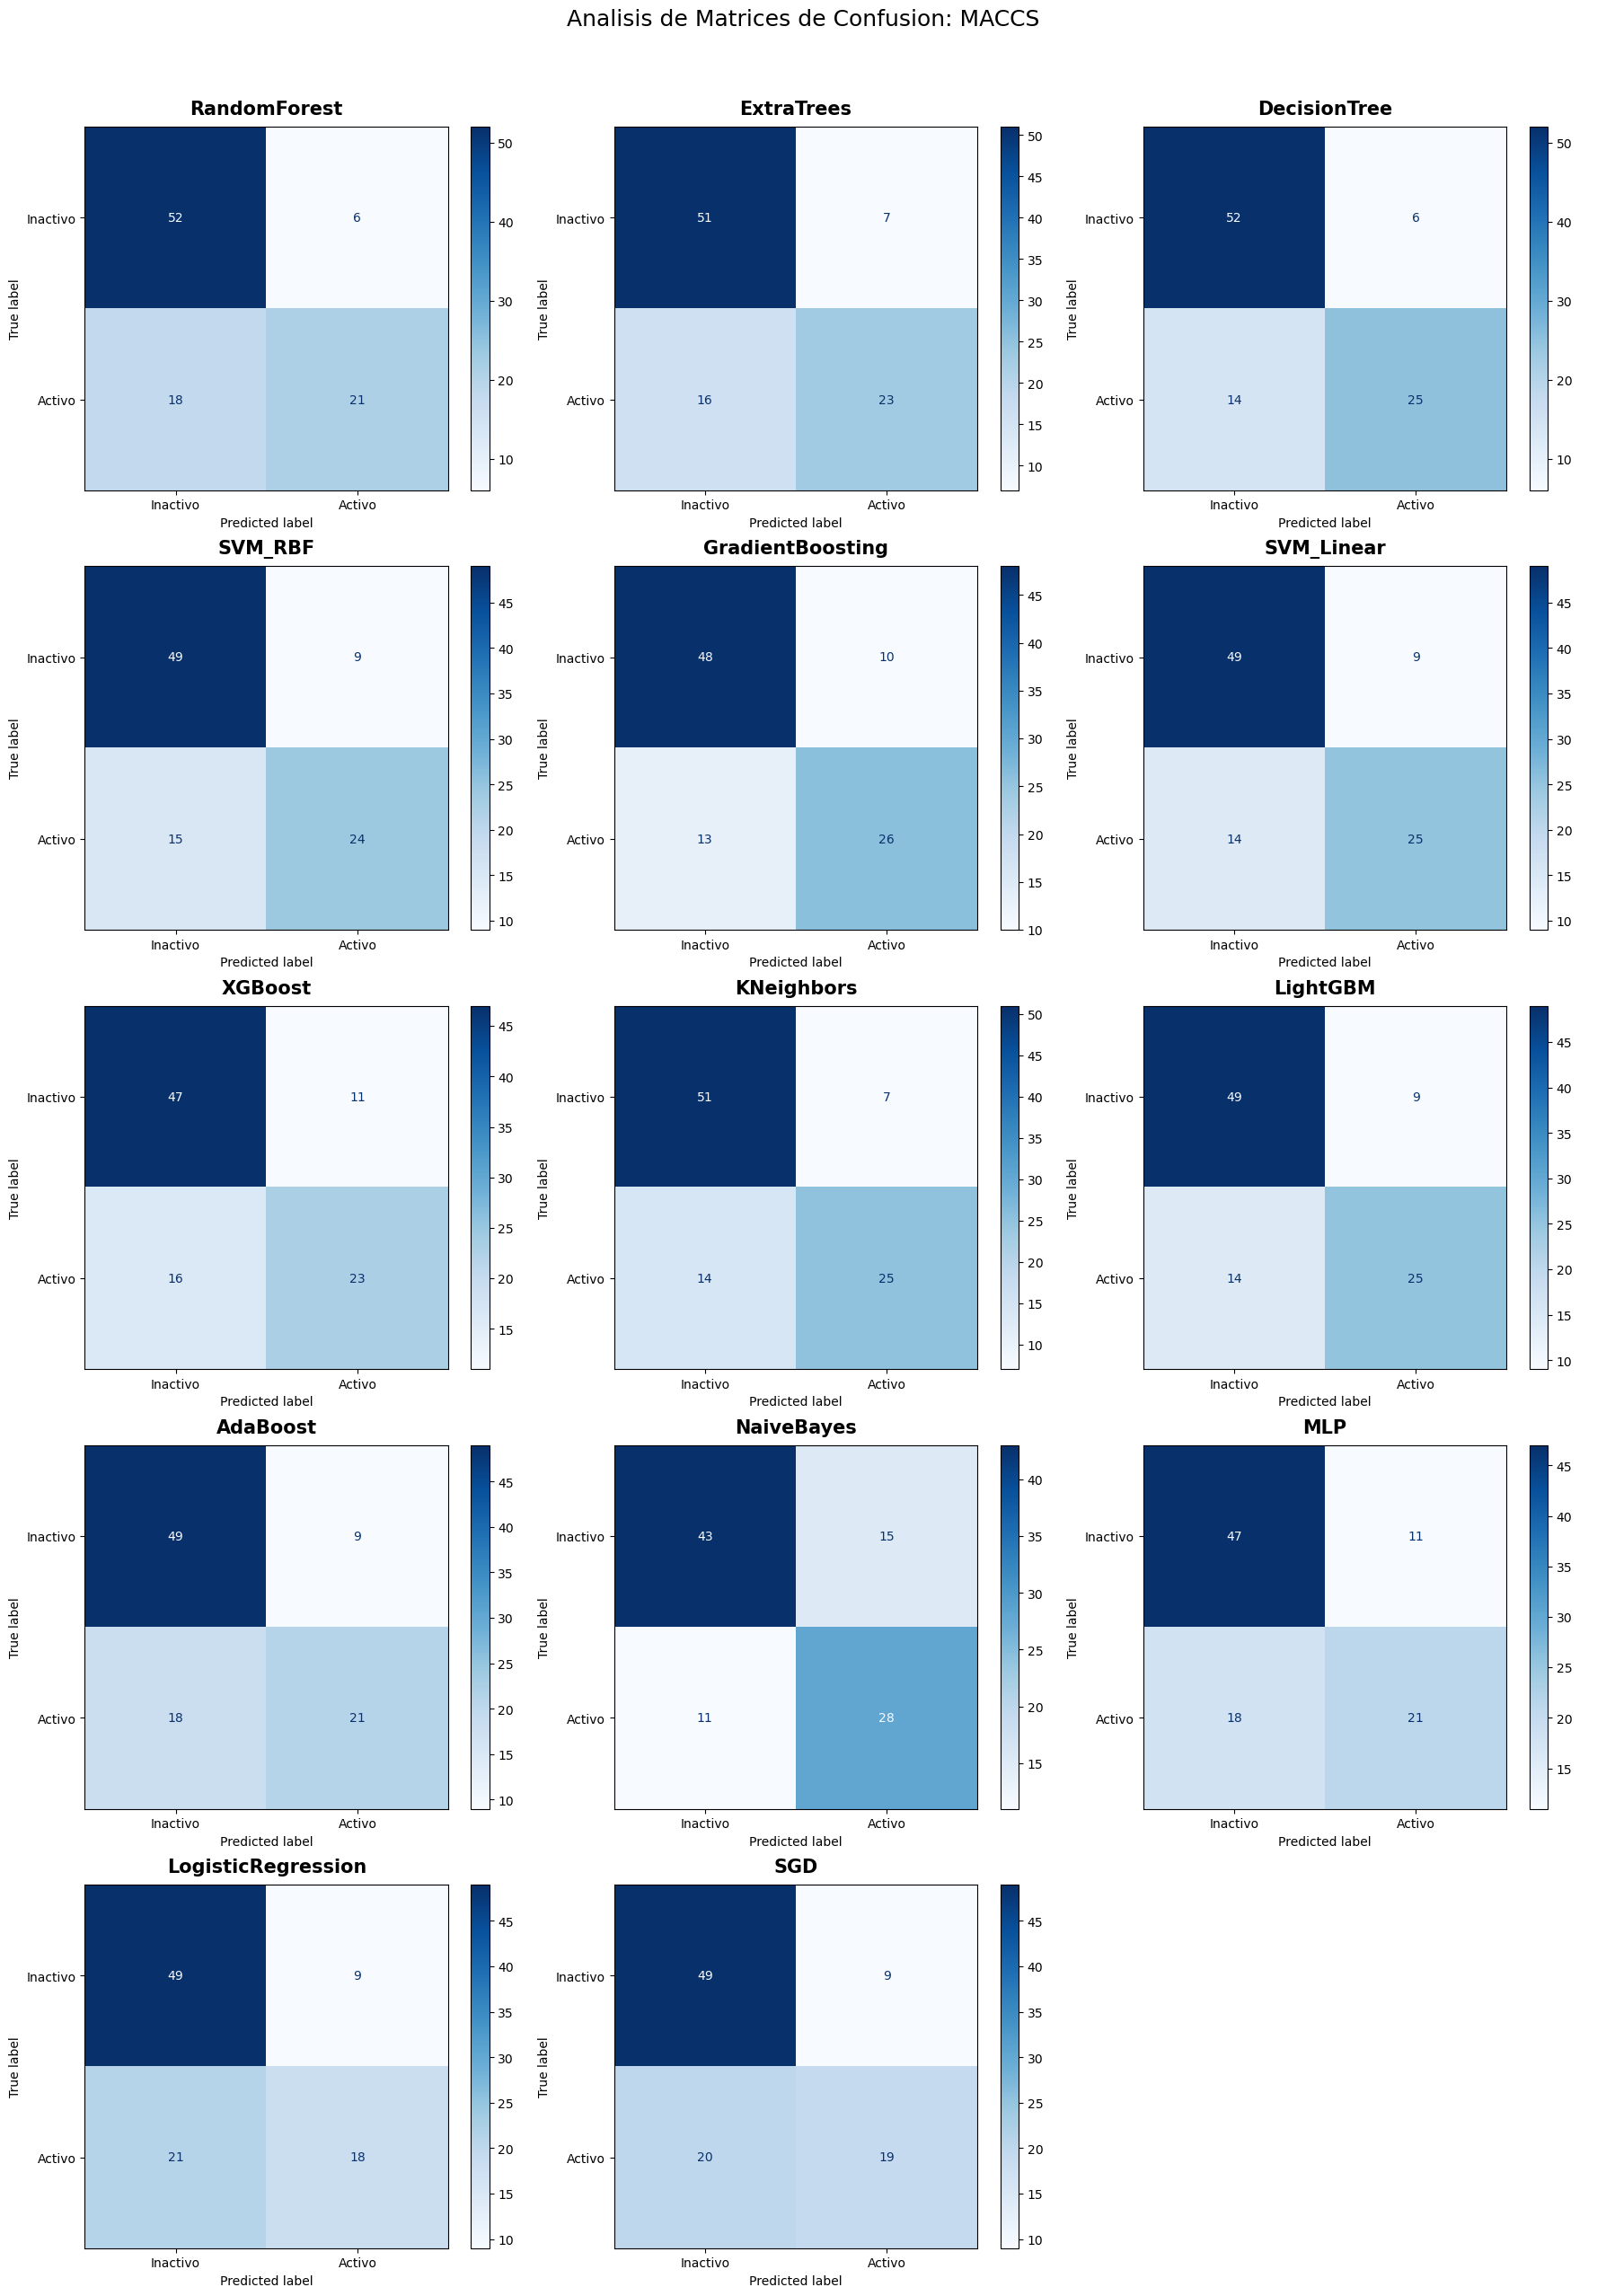

In [12]:
def plot_matrices_final(method_name, results_df, estimators_dict, feature_sets_dict):
    method_results = results_df[results_df["feature_set"].str.contains(method_name, case=False)]
    n_models = len(method_results)
    if n_models == 0: return
    cols = 3
    rows = math.ceil(n_models / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(18, rows * 5))
    axes = axes.flatten()
    for i, (_, row) in enumerate(method_results.iterrows()):
        model_name = row['model']
        fs_name = row['feature_set']
        key = f"{model_name}__{fs_name}"
        est = estimators_dict[key]
        fs_cols = feature_sets_dict[fs_name]
        y_pred = est.predict(X_test_full[fs_cols])
        cm = confusion_matrix(y_test, y_pred)
        disp = ConfusionMatrixDisplay(cm, display_labels=["Inactivo", "Activo"])
        disp.plot(ax=axes[i], colorbar=True, cmap="Blues")
        axes[i].set_title(f"{model_name}", fontsize=15, pad=10, fontweight='bold')
    for j in range(i + 1, len(axes)):
        axes[j].axis('off')
    plt.suptitle(f"Analisis de Matrices de Confusion: {method_name.upper()}", fontsize=18, y=1.02)
    plt.tight_layout()
    plt.savefig(f'{FIGURAS}/paso7_confusion_{method_name}_final_maccs.png', dpi=150, bbox_inches="tight")
    plt.show()

plot_matrices_final("maccs", df_results, best_estimators, feature_sets)


# 5.2 Realización de las curvas ROC

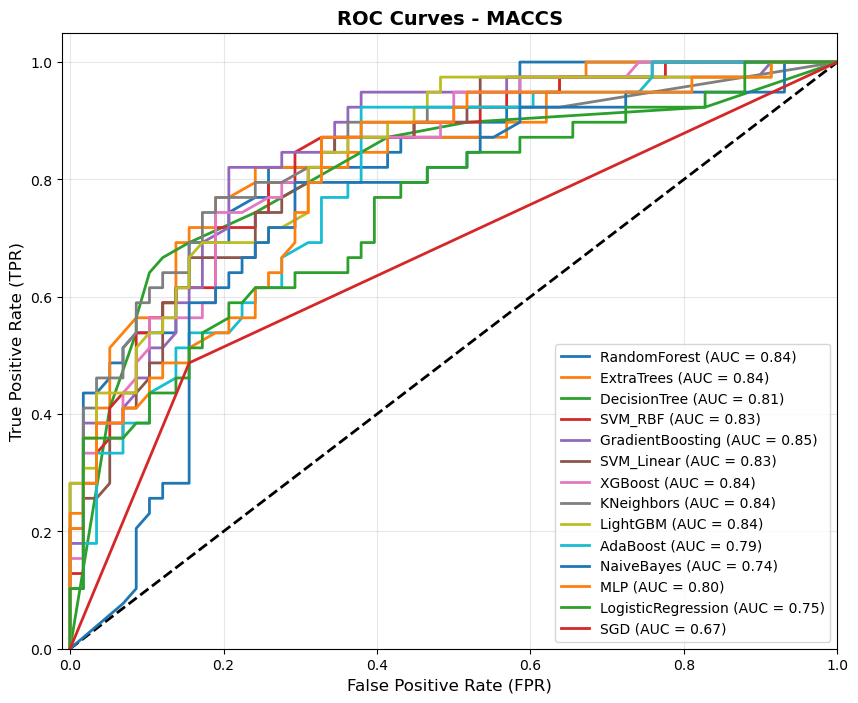

In [13]:
def plot_roc_curves_by_method(method_name, results_df, estimators_dict, feature_sets_dict):
    method_results = results_df[results_df["feature_set"].str.contains(method_name, case=False)]
    plt.figure(figsize=(10, 8))
    plt.plot([0, 1], [0, 1], 'k--', lw=2)

    for _, row in method_results.iterrows():
        model_name = row['model']
        fs_name = row['feature_set']
        key = f"{model_name}__{fs_name}"
        est = estimators_dict[key]
        fs_cols = feature_sets_dict[fs_name]
        if hasattr(est, "predict_proba"):
            y_score = est.predict_proba(X_test_full[fs_cols])[:, 1]
        else:
            y_score = est.decision_function(X_test_full[fs_cols])
        fpr, tpr, _ = roc_curve(y_test, y_score)
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, lw=2, label=f'{model_name} (AUC = {roc_auc:.2f})')

    plt.xlim([-0.01, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate (FPR)', fontsize=12)
    plt.ylabel('True Positive Rate (TPR)', fontsize=12)
    plt.title(f'ROC Curves - {method_name.upper()}', fontsize=14, fontweight='bold')
    plt.legend(loc="lower right", fontsize=10)
    plt.grid(alpha=0.3)
    plt.savefig(f'{FIGURAS}/paso7_roc_comparison_{method_name}_maccs.png', dpi=150, bbox_inches="tight")
    plt.show()

plot_roc_curves_by_method("Maccs", df_results, best_estimators, feature_sets)


# 5.3 Ranking de los modelos

In [14]:
best_est = best_estimators[best_key]
best_fs  = feature_sets[best_row["feature_set"]]
y_pred   = best_est.predict(X_test_full[best_fs])

print(f"\n{'='*60}")
print(f"MEJOR MODELO (seleccionado por balanced score): {best_row['model']}")
print(f"Feature set  : {best_row['feature_set']} ({int(best_row['n_features'])} descriptores)")
print(f"CV ROC-AUC   : {best_row['cv_roc_auc_mean']:.4f} +/- {best_row['cv_roc_auc_std']:.4f}")
print(f"{'='*60}")
print(classification_report(y_test, y_pred, target_names=["Inactivo", "Activo"]))
print(f"MCC = {matthews_corrcoef(y_test, y_pred):.4f}")
try:
    y_prob = best_est.predict_proba(X_test_full[best_fs])[:, 1]
    print(f"ROC-AUC (test) = {roc_auc_score(y_test, y_prob):.4f}")
except AttributeError:
    pass

pd.DataFrame(
    classification_report(y_test, y_pred,
                           target_names=["Inactivo", "Activo"],
                           output_dict=True)
).T.to_csv(f'{OUTPUT_DIR_ML}/paso7_report_mejor_modelo_maccs.csv')

print(f"\nGraficos y reportes del paso 7 guardados.")



MEJOR MODELO (seleccionado por balanced score): RandomForest
Feature set  : maccs_full (167 descriptores)
CV ROC-AUC   : 0.8447 +/- 0.0352
              precision    recall  f1-score   support

    Inactivo       0.74      0.90      0.81        58
      Activo       0.78      0.54      0.64        39

    accuracy                           0.75        97
   macro avg       0.76      0.72      0.72        97
weighted avg       0.76      0.75      0.74        97

MCC = 0.4759
ROC-AUC (test) = 0.8426

Graficos y reportes del paso 7 guardados.


# 6. Estimación robusta de rendimiento

In [15]:
# Con ~380 compuestos de train, un único split 80/20 es muy sensible a qué
# compuestos caen en cada lado. Repetimos la validación muchas veces para
# obtener una media +/- desviación estándar en vez de un solo número.

from sklearn.model_selection import StratifiedGroupKFold as _SGKF

n_repeats = 10
aucs, mccs = [], []

for rep in range(n_repeats):
    cv_rep = _SGKF(n_splits=5, shuffle=True, random_state=rep)
    for tr_i, te_i in cv_rep.split(X_full, y, groups=groups_all):
        pipe_rep = clone(best_est)
        pipe_rep.fit(X_full.iloc[tr_i], y.iloc[tr_i])
        prob = pipe_rep.predict_proba(X_full.iloc[te_i])[:, 1]
        pred = pipe_rep.predict(X_full.iloc[te_i])
        if len(np.unique(y.iloc[te_i])) > 1:
            aucs.append(roc_auc_score(y.iloc[te_i], prob))
        mccs.append(matthews_corrcoef(y.iloc[te_i], pred))

print(f"ROC-AUC  (repeated group-CV, {n_repeats}x5-fold): "
      f"{np.mean(aucs):.3f} +/- {np.std(aucs):.3f}")
print(f"MCC      (repeated group-CV, {n_repeats}x5-fold): "
      f"{np.mean(mccs):.3f} +/- {np.std(mccs):.3f}")



ROC-AUC  (repeated group-CV, 10x5-fold): 0.848 +/- 0.040
MCC      (repeated group-CV, 10x5-fold): 0.517 +/- 0.091


# 7. Control de y-scrambling

AUC real del modelo (test)     : 0.843
AUC con y-scrambling (20 veces) : 0.493 +/- 0.079
Si el AUC scrambled se acerca a 0.5, el modelo real está aprendiendo señal genuina y no ruido/artefactos.


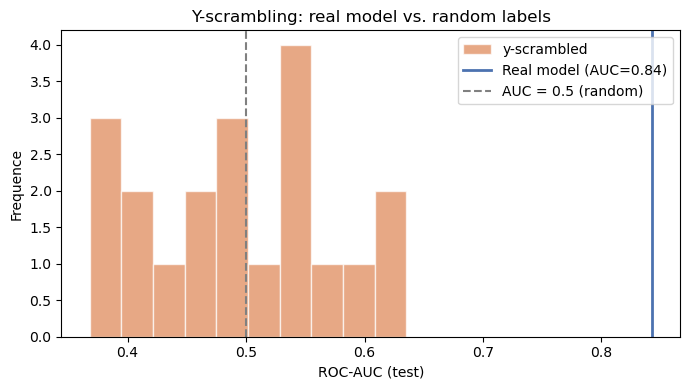

In [16]:
# Si el modelo obtiene buen AUC incluso con las etiquetas barajadas
# aleatoriamente, es señal de que está aprendiendo estructura espuria del
# dataset (p.ej. artefactos del split o de las features) y no una relación
# estructura-actividad real. Con etiquetas al azar el AUC esperado es ~0.5.

n_scrambles = 20
scrambled_aucs = []

rng = np.random.RandomState(RANDOM_STATE)
for i in range(n_scrambles):
    y_shuffled = pd.Series(rng.permutation(y_train.values), index=y_train.index)
    m = clone(best_est)
    m.fit(X_train_full[best_fs], y_shuffled)
    p = m.predict_proba(X_test_full[best_fs])[:, 1]
    scrambled_aucs.append(roc_auc_score(y_test, p))

print(f"AUC real del modelo (test)     : {roc_auc_score(y_test, y_prob):.3f}")
print(f"AUC con y-scrambling ({n_scrambles} veces) : "
      f"{np.mean(scrambled_aucs):.3f} +/- {np.std(scrambled_aucs):.3f}")
print("Si el AUC scrambled se acerca a 0.5, el modelo real está aprendiendo "
      "señal genuina y no ruido/artefactos.")

plt.figure(figsize=(7, 4))
plt.hist(scrambled_aucs, bins=10, color='#DD8452', alpha=0.7, edgecolor='white',
         label='y-scrambled')
plt.axvline(roc_auc_score(y_test, y_prob), color='#4C72B0', linewidth=2,
            label=f"Real model (AUC={roc_auc_score(y_test, y_prob):.2f})")
plt.axvline(0.5, color='gray', linestyle='--', label='AUC = 0.5 (random)')
plt.xlabel('ROC-AUC (test)')
plt.ylabel('Frequence')
plt.title('Y-scrambling: real model vs. random labels')
plt.legend()
plt.tight_layout()
plt.savefig(f'{FIGURAS}/paso7b_yscrambling_{best_row["model"]}_maccs.png', dpi=150, bbox_inches='tight')
plt.show()


# 8. Dominio de aplicabilidad-kNN

TOP 3 MODELS SELECTED FOR THE APPLICABILITY DOMAIN
       model feature_set  n_features  cv_roc_auc_mean  roc_auc_test
RandomForest  maccs_full         167         0.844699      0.842617
  ExtraTrees  maccs_full         167         0.847206      0.843943
DecisionTree  maccs_full         167         0.768154      0.812997

Descriptors (k)          : 167
Train compounds (n)      : 373
kNN-AD threshold         : 13.3726

Train - mean distance (mean +/- std): 6.7510 +/- 3.3108
Test  - inside the AD    : 95 (97.9%)
Test  - outside the AD   : 2 (2.1%)


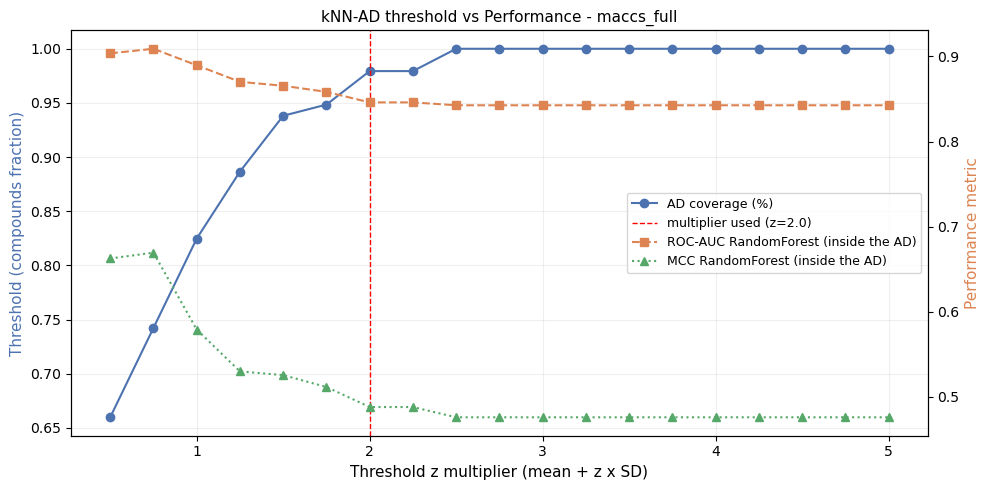

resultados dominio de aplicabilidad maccs/paso8_ad_coverage_maccs_full_maccs.png guardado.
split  in_AD
test   0          2
       1         95
train  1        373
resultados dominio de aplicabilidad maccs/paso8_knnAD_maccs_full_maccs.csv guardado.

[1/3] MODELO: RandomForest  |  Feature set: maccs_full


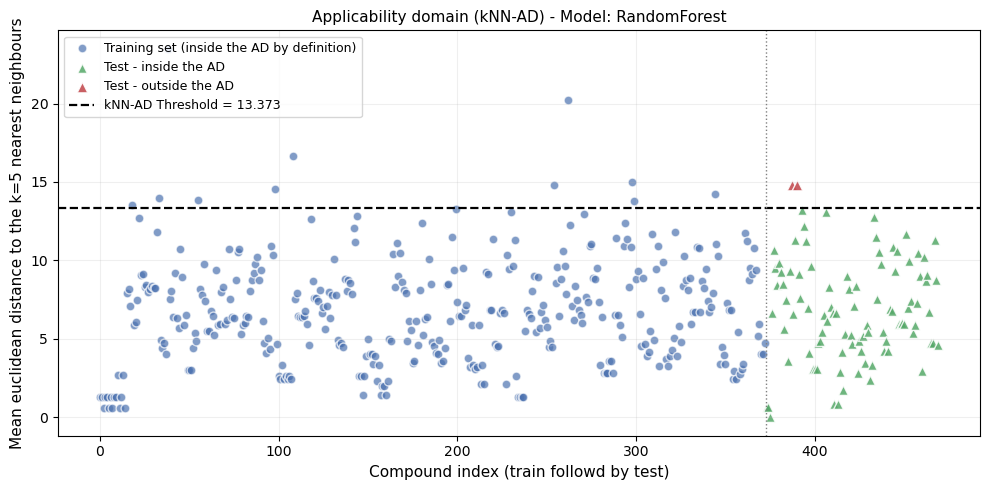

resultados dominio de aplicabilidad maccs/paso8_knnAD_scatter_top1_RandomForest_maccs.png guardado.

-- Test completed (n=97) --
  Accuracy  : 0.7526
  F1        : 0.6364
  MCC       : 0.4759
  ROC-AUC   : 0.8426

-- Test inside the AD (n=95) --
  Accuracy  : 0.7579
  F1        : 0.6349
  MCC       : 0.4880
  ROC-AUC   : 0.8460

-- Test outside the AD (n=2) --
  Accuracy  : 0.5000
  F1        : 0.6667
  MCC       : 0.0000
  ROC-AUC   : 0.5000
resultados dominio de aplicabilidad maccs/paso8_ad_metrics_top1_RandomForest_maccs.csv guardado.

[2/3] MODELO: ExtraTrees  |  Feature set: maccs_full


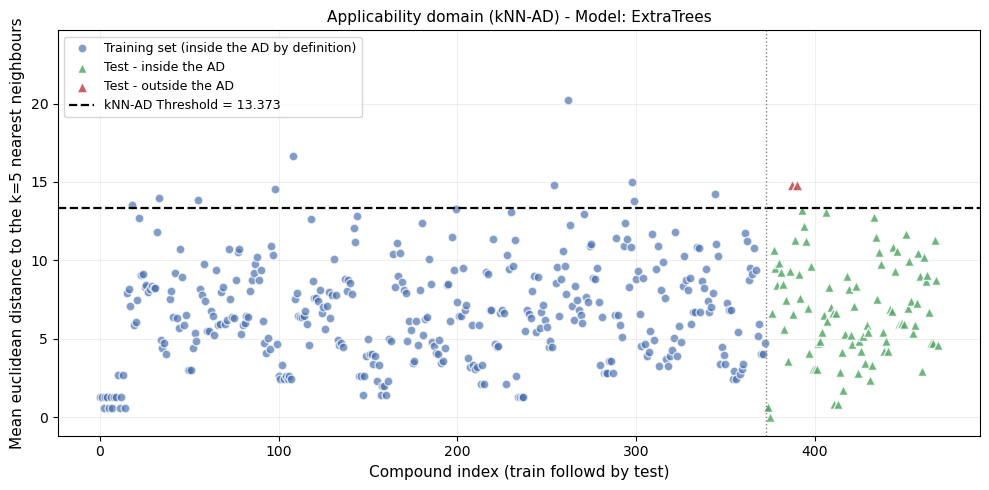

resultados dominio de aplicabilidad maccs/paso8_knnAD_scatter_top2_ExtraTrees_maccs.png guardado.

-- Test completed (n=97) --
  Accuracy  : 0.7629
  F1        : 0.6667
  MCC       : 0.4976
  ROC-AUC   : 0.8439

-- Test inside the AD (n=95) --
  Accuracy  : 0.7684
  F1        : 0.6667
  MCC       : 0.5090
  ROC-AUC   : 0.8470

-- Test outside the AD (n=2) --
  Accuracy  : 0.5000
  F1        : 0.6667
  MCC       : 0.0000
  ROC-AUC   : 0.5000
resultados dominio de aplicabilidad maccs/paso8_ad_metrics_top2_ExtraTrees_maccs.csv guardado.

[3/3] MODELO: DecisionTree  |  Feature set: maccs_full


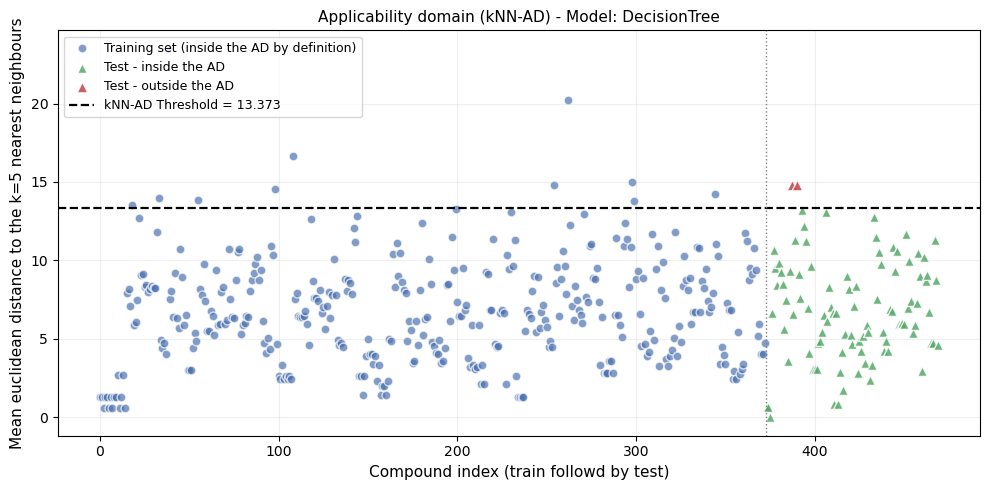

resultados dominio de aplicabilidad maccs/paso8_knnAD_scatter_top3_DecisionTree_maccs.png guardado.

-- Test completed (n=97) --
  Accuracy  : 0.7938
  F1        : 0.7143
  MCC       : 0.5652
  ROC-AUC   : 0.8130

-- Test inside the AD (n=95) --
  Accuracy  : 0.8000
  F1        : 0.7246
  MCC       : 0.5774
  ROC-AUC   : 0.8296

-- Test outside the AD (n=2) --
  Accuracy  : 0.5000
  F1        : 0.0000
  MCC       : 0.0000
  ROC-AUC   : 0.5000
resultados dominio de aplicabilidad maccs/paso8_ad_metrics_top3_DecisionTree_maccs.csv guardado.

RESUMEN COMPARATIVO - TOP 3 MODELOS (mismo AD, distinto clasificador)
 rank        model feature_set  roc_auc_all  roc_auc_in_AD  mcc_all  mcc_in_AD
    1 RandomForest  maccs_full       0.8426         0.8460   0.4759     0.4880
    2   ExtraTrees  maccs_full       0.8439         0.8470   0.4976     0.5090
    3 DecisionTree  maccs_full       0.8130         0.8296   0.5652     0.5774

paraso8_summary_top3_maccs.csv guardado.


In [17]:
# Una molecula se considera DENTRO del dominio si esta "cerca" (en el espacio
# de descriptores estandarizado) de las moleculas del training set. Este
# metodo es agnostico al algoritmo de ML: depende solo del feature set, no
# del clasificador.
#
# Algoritmo (kNN-AD):
#   1. Estandarizar los descriptores con la media/SD del TRAIN set.
#   2. Para cada compuesto de train, calcular la distancia euclidea media a
#      sus k=5 vecinos mas cercanos DENTRO DEL PROPIO TRAIN (excluyendo el
#      compuesto consigo mismo, para no inflar artificialmente la distancia
#      media con un cero).
#   3. Umbral = media + 2 x desviacion estandar de esas distancias en train.
#   4. Para cada compuesto de test, calcular su distancia media a los k=5
#      vecinos mas cercanos DEL TRAIN. Si esa distancia < umbral, esta
#      dentro del AD.

def metrics_summary(y_true, y_pred, y_prob, label):
    print(f"\n-- {label} (n={len(y_true)}) --")
    print(f"  Accuracy  : {accuracy_score(y_true, y_pred):.4f}")
    print(f"  F1        : {f1_score(y_true, y_pred):.4f}")
    print(f"  MCC       : {matthews_corrcoef(y_true, y_pred):.4f}")
    if len(np.unique(y_true)) > 1:
        print(f"  ROC-AUC   : {roc_auc_score(y_true, y_prob):.4f}")
    return {
        'subset'  : label,
        'n'       : len(y_true),
        'accuracy': accuracy_score(y_true, y_pred),
        'f1'      : f1_score(y_true, y_pred),
        'mcc'     : matthews_corrcoef(y_true, y_pred),
        'roc_auc' : roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) > 1 else np.nan,
    }


def knn_ad(X_train: pd.DataFrame, X_test: pd.DataFrame, n_neighbors: int = 5, z: float = 2.0):
    scaler_ad = StandardScaler()
    X_train_ad = scaler_ad.fit_transform(X_train)
    X_test_ad  = scaler_ad.transform(X_test)

    nn = NearestNeighbors(n_neighbors=n_neighbors + 1)  # +1 porque el propio punto sera su vecino 0 en train
    nn.fit(X_train_ad)

    # Distancias en TRAIN: se excluye la columna 0 (distancia a si mismo = 0)
    distances_train, _ = nn.kneighbors(X_train_ad)
    mean_dist_train = distances_train[:, 1:].mean(axis=1)

    threshold = mean_dist_train.mean() + z * mean_dist_train.std()

    # Distancias en TEST: aqui SI se usan los n_neighbors mas cercanos del
    # train tal cual (el punto de test no esta en el training set, no hay
    # auto-match que excluir). Se reutiliza el mismo objeto nn (ya ajustado
    # con n_neighbors+1) y se descarta la ultima columna para mantener k=5.
    distances_test, _ = nn.kneighbors(X_test_ad)
    mean_dist_test = distances_test[:, :n_neighbors].mean(axis=1)

    return mean_dist_train, mean_dist_test, threshold, scaler_ad, nn


def plot_ad_scatter(model_name, mean_dist_train, mean_dist_test, threshold,
                     mask_ad, fs_name, model_tag):
    """
    Grafico de puntos del dominio de aplicabilidad (kNN-AD), en vez de
    histograma: cada compuesto es un punto (train y test), con su distancia
    media a los k=5 vecinos mas cercanos del train en el eje Y, y una linea
    horizontal con el umbral. Permite ver de un vistazo que compuestos
    concretos caen dentro/fuera del AD.
    """
    n_train = len(mean_dist_train)
    idx_train = np.arange(n_train)
    idx_test  = np.arange(n_train, n_train + len(mean_dist_test))

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.scatter(idx_train, mean_dist_train, color="#4C72B0", alpha=0.7,
               edgecolor="white", s=40, label="Training set (inside the AD by definition)")
    ax.scatter(idx_test[mask_ad], mean_dist_test[mask_ad], color="#55A868", alpha=0.85,
               edgecolor="white", s=50, marker="^", label="Test - inside the AD")
    ax.scatter(idx_test[~mask_ad], mean_dist_test[~mask_ad], color="#C44E52", alpha=0.9,
               edgecolor="white", s=60, marker="^", label="Test - outside the AD")
    ax.axhline(threshold, color="black", linestyle="--", linewidth=1.6,
               label=f"kNN-AD Threshold = {threshold:.3f}")
    ax.axvline(n_train - 0.5, color="gray", linestyle=":", linewidth=1)
    ax.set_xlabel("Compound index (train followd by test)", fontsize=11)
    ax.set_ylabel("Mean euclidean distance to the k=5 nearest neighbours", fontsize=11)
    ax.set_title(f"Applicability domain (kNN-AD) - Model: {model_name}",
                 fontsize=11)
    ax.legend(fontsize=9, loc="upper left")
    ax.grid(alpha=0.2)
    plt.tight_layout()
    out_scatter = f'{OUTPUT_DIR_AD}/paso8_knnAD_scatter_{model_tag}_maccs.png'
    plt.savefig(out_scatter, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'{out_scatter} guardado.')


top3 = df_results.head(3).reset_index(drop=True)

print("=" * 60)
print("TOP 3 MODELS SELECTED FOR THE APPLICABILITY DOMAIN")
print("=" * 60)
cols_show = ["model", "feature_set", "n_features", "cv_roc_auc_mean", "roc_auc_test"]
print(top3[cols_show].to_string(index=False))
print()

fs_name = top3.iloc[0]["feature_set"]   # "maccs_full" (unico feature set en MACCS)
fs_cols = feature_sets[fs_name]
best_key = f"{top3.iloc[0]['model']}__{fs_name}"

# ── kNN-AD: se calcula UNA vez (unico feature set, agnostico al modelo) ─────
mean_dist_train, mean_dist_test, threshold, scaler_ad, nn_ad = knn_ad(
    X_train_full[fs_cols], X_test_full[fs_cols], n_neighbors=5, z=2.0
)

print(f"Descriptors (k)          : {len(fs_cols)}")
print(f"Train compounds (n)      : {len(X_train_full)}")
print(f"kNN-AD threshold         : {threshold:.4f}")

mask_ad = mean_dist_test < threshold
print()
print(f"Train - mean distance (mean +/- std): {mean_dist_train.mean():.4f} +/- {mean_dist_train.std():.4f}")
print(f"Test  - inside the AD    : {mask_ad.sum()} ({mask_ad.mean():.1%})")
print(f"Test  - outside the AD   : {(~mask_ad).sum()} ({(~mask_ad).mean():.1%})")

# ── Cobertura del AD vs rendimiento del top1, variando el multiplicador z ───
z_values = np.arange(0.5, 5.1, 0.25)
top1_est = best_estimators[best_key]
y_pred_top1 = top1_est.predict(X_test_full[fs_cols])
y_prob_top1 = (top1_est.predict_proba(X_test_full[fs_cols])[:, 1]
               if hasattr(top1_est, "predict_proba")
               else top1_est.decision_function(X_test_full[fs_cols]))

coverages, aucs_cov, mccs_cov = [], [], []
for zval in z_values:
    thr = mean_dist_train.mean() + zval * mean_dist_train.std()
    mask = mean_dist_test < thr
    coverages.append(mask.mean())
    if mask.sum() > 5 and len(np.unique(y_test[mask])) > 1:
        aucs_cov.append(roc_auc_score(y_test[mask], y_prob_top1[mask]))
        mccs_cov.append(matthews_corrcoef(y_test[mask], y_pred_top1[mask]))
    else:
        aucs_cov.append(np.nan)
        mccs_cov.append(np.nan)

fig, ax1 = plt.subplots(figsize=(10, 5))
ax2 = ax1.twinx()
ax1.plot(z_values, coverages, 'o-',  color='#4C72B0', label='AD coverage (%)')
ax2.plot(z_values, aucs_cov,  's--', color='#DD8452', label=f'ROC-AUC {top3.iloc[0]["model"]} (inside the AD)')
ax2.plot(z_values, mccs_cov,  '^:',  color='#55A868', label=f'MCC {top3.iloc[0]["model"]} (inside the AD)')
ax1.axvline(2.0, color='red', linestyle='--', linewidth=1, label='multiplier used (z=2.0)')
ax1.set_xlabel('Threshold z multiplier (mean + z x SD)', fontsize=11)
ax1.set_ylabel('Threshold (compounds fraction)', fontsize=11, color='#4C72B0')
ax2.set_ylabel('Performance metric', fontsize=11, color='#DD8452')
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, fontsize=9, loc='center right')
ax1.set_title(f'kNN-AD threshold vs Performance - {fs_name}', fontsize=11)
ax1.grid(alpha=0.2)
plt.tight_layout()
out_cov = f'{OUTPUT_DIR_AD}/paso8_ad_coverage_{fs_name}_maccs.png'
plt.savefig(out_cov, dpi=150, bbox_inches='tight')
plt.show()
print(f'{out_cov} guardado.')

# ── Guardar distancia media por compuesto (train + test) ────────────────────
df_ad_train = pd.DataFrame({
    'smiles_std'      : df_final.loc[train_orig_idx, 'smiles_std'].values,
    'split'           : 'train',
    'mean_dist_5nn'   : mean_dist_train,
    'label'           : y_train.values,
    'in_AD'           : 1,  # por definicion, el training set siempre esta dentro de su propio dominio
    'feature_set'     : fs_name,
})
df_ad_test = pd.DataFrame({
    'smiles_std'      : df_final.loc[test_orig_idx, 'smiles_std'].values,
    'split'           : 'test',
    'mean_dist_5nn'   : mean_dist_test,
    'label'           : y_test.values,
    'in_AD'           : mask_ad.astype(int),
    'feature_set'     : fs_name,
})
df_ad_all = pd.concat([df_ad_train, df_ad_test], ignore_index=True)
out_dist = f'{OUTPUT_DIR_AD}/paso8_knnAD_{fs_name}_maccs.csv'
df_ad_all.to_csv(out_dist, index=False)
print(df_ad_all.groupby(['split', 'in_AD']).size().rename('n_compuestos').to_string())
print(f'{out_dist} guardado.')

# =============================================================================
# Grafico de puntos (AD) + rendimiento dentro / fuera del AD, POR CADA UNO de los 3 modelos
# =============================================================================
summary_rows = []
for rank, row in top3.iterrows():
    rank += 1
    model_name = row["model"]
    key        = f"{model_name}__{fs_name}"
    est        = best_estimators[key]
    model_tag  = f"top{rank}_{model_name}"

    print("\n" + "=" * 60)
    print(f"[{rank}/3] MODELO: {model_name}  |  Feature set: {fs_name}")
    print("=" * 60)

    y_pred_test = est.predict(X_test_full[fs_cols])
    y_prob_test = (est.predict_proba(X_test_full[fs_cols])[:, 1]
                   if hasattr(est, "predict_proba")
                   else est.decision_function(X_test_full[fs_cols]))

    # Grafico de puntos individual para este modelo (mismo criterio kNN-AD
    # de siempre, solo cambia la visualizacion: puntos en vez de histograma)
    plot_ad_scatter(model_name, mean_dist_train, mean_dist_test, threshold,
                     mask_ad, fs_name, model_tag)

    r_all = metrics_summary(y_test, y_pred_test, y_prob_test, 'Test completed')
    r_ad  = metrics_summary(y_test[mask_ad], y_pred_test[mask_ad], y_prob_test[mask_ad], 'Test inside the AD')
    r_out = metrics_summary(y_test[~mask_ad], y_pred_test[~mask_ad], y_prob_test[~mask_ad], 'Test outside the AD')

    df_ad_metrics = pd.DataFrame([r_all, r_ad, r_out])
    df_ad_metrics['model']       = model_name
    df_ad_metrics['feature_set'] = fs_name
    out_metrics = f'{OUTPUT_DIR_AD}/paso8_ad_metrics_{model_tag}_maccs.csv'
    df_ad_metrics.to_csv(out_metrics, index=False)
    print(f"{out_metrics} guardado.")

    summary_rows.append({
        'rank'          : rank,
        'model'         : model_name,
        'feature_set'   : fs_name,
        'roc_auc_all'   : round(roc_auc_score(y_test, y_prob_test), 4),
        'roc_auc_in_AD' : round(r_ad['roc_auc'], 4) if not np.isnan(r_ad['roc_auc']) else np.nan,
        'mcc_all'       : round(r_all['mcc'], 4),
        'mcc_in_AD'     : round(r_ad['mcc'], 4),
    })

df_summary = pd.DataFrame(summary_rows)
df_summary.to_csv(f'{OUTPUT_DIR_AD}/paso8_summary_top3_maccs.csv', index=False)
print("\n" + "=" * 60)
print("RESUMEN COMPARATIVO - TOP 3 MODELOS (mismo AD, distinto clasificador)")
print("=" * 60)
print(df_summary.to_string(index=False))
print('\nparaso8_summary_top3_maccs.csv guardado.')

# 10. Interpretabilidad: Permutation Feature Importance


[1/3] Permutation importance: RandomForest | maccs_full (167 bits MACCS)
Top 20 bits MACCS por importancia (ROC-AUC):
descriptor  importance_mean  importance_std       effect
  MACCS_66         0.006970        0.002618 positivo (+)
  MACCS_41         0.006307        0.003211 positivo (+)
 MACCS_153         0.004671        0.004669 negativo (-)
  MACCS_22         0.004590        0.002457 positivo (+)
  MACCS_47         0.003360        0.001427 negativo (-)
 MACCS_115         0.003249        0.005320 positivo (+)
  MACCS_54         0.003183        0.006801 positivo (+)
 MACCS_135         0.003124        0.003990 negativo (-)
  MACCS_80         0.003087        0.004013 negativo (-)
  MACCS_43         0.002837        0.002863 positivo (+)
  MACCS_23         0.002697        0.002803 negativo (-)
  MACCS_89         0.002667        0.003084 positivo (+)
 MACCS_105         0.002417        0.002355 negativo (-)
  MACCS_85         0.002387        0.001741 positivo (+)
 MACCS_106         0.00231

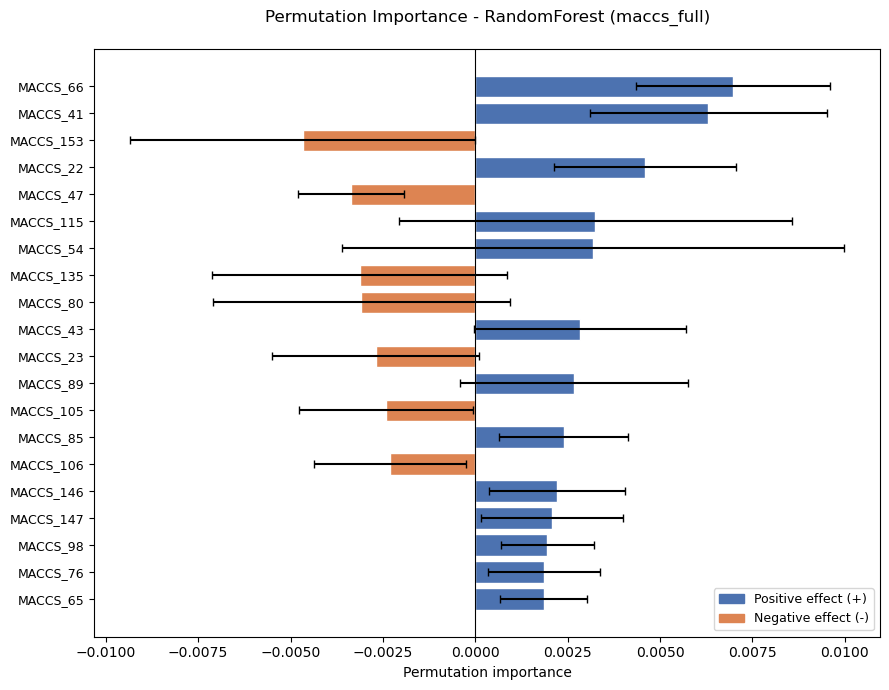

figuras/MACCs/paso9_permutation_importance_top1_RandomForest_maccs.png guardado.

[2/3] Permutation importance: ExtraTrees | maccs_full (167 bits MACCS)
Top 20 bits MACCS por importancia (ROC-AUC):
descriptor  importance_mean  importance_std       effect
 MACCS_144         0.008215        0.004387 negativo (-)
 MACCS_115         0.007567        0.005150 positivo (+)
  MACCS_41         0.006764        0.009079 positivo (+)
 MACCS_153         0.005629        0.005083 negativo (-)
  MACCS_69         0.005548        0.002544 positivo (+)
  MACCS_22         0.005475        0.003426 positivo (+)
  MACCS_66         0.005261        0.003861 positivo (+)
 MACCS_152         0.004649        0.004555 positivo (+)
  MACCS_54         0.004509        0.004884 positivo (+)
  MACCS_94         0.003979        0.001704 positivo (+)
 MACCS_112         0.003795        0.002235 positivo (+)
 MACCS_121         0.003492        0.003956 negativo (-)
  MACCS_43         0.002999        0.006113 positivo (+)
  MA

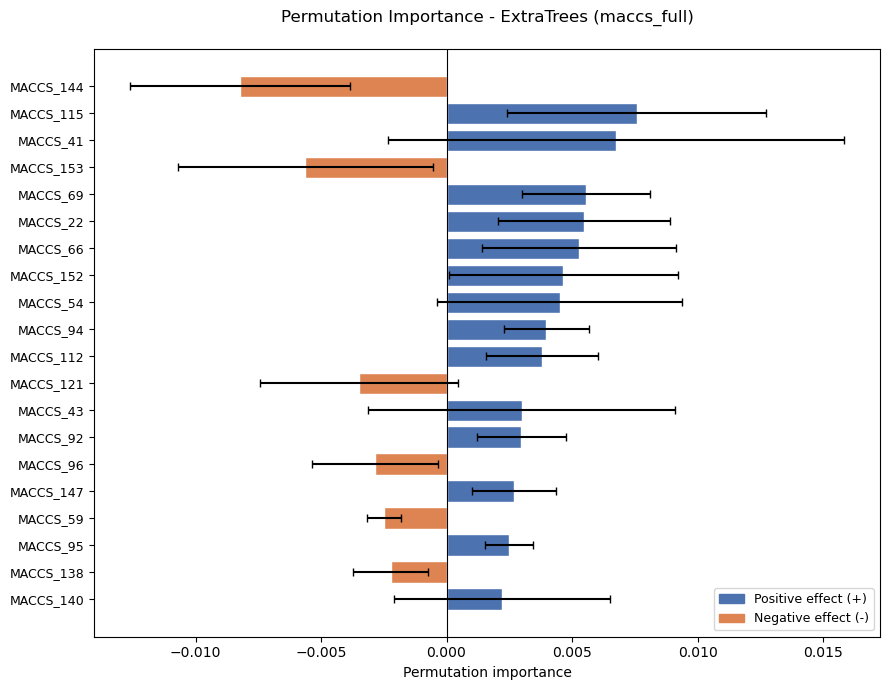

figuras/MACCs/paso9_permutation_importance_top2_ExtraTrees_maccs.png guardado.

[3/3] Permutation importance: DecisionTree | maccs_full (167 bits MACCS)
Top 20 bits MACCS por importancia (ROC-AUC):
descriptor  importance_mean  importance_std       effect
 MACCS_126         0.135507        0.035005 positivo (+)
 MACCS_140         0.120653        0.047359 positivo (+)
 MACCS_115         0.106049        0.039546 positivo (+)
  MACCS_41         0.088351        0.025942 positivo (+)
 MACCS_129         0.077188        0.017299 positivo (+)
 MACCS_121         0.058046        0.017974 positivo (+)
  MACCS_93         0.047347        0.022527 positivo (+)
  MACCS_23         0.047067        0.027129 negativo (-)
  MACCS_89         0.046286        0.021188 positivo (+)
 MACCS_145         0.035838        0.019757 positivo (+)
 MACCS_138         0.028301        0.011873 negativo (-)
 MACCS_112         0.021242        0.020433 positivo (+)
 MACCS_150         0.016792        0.017067 negativo (-)
  MA

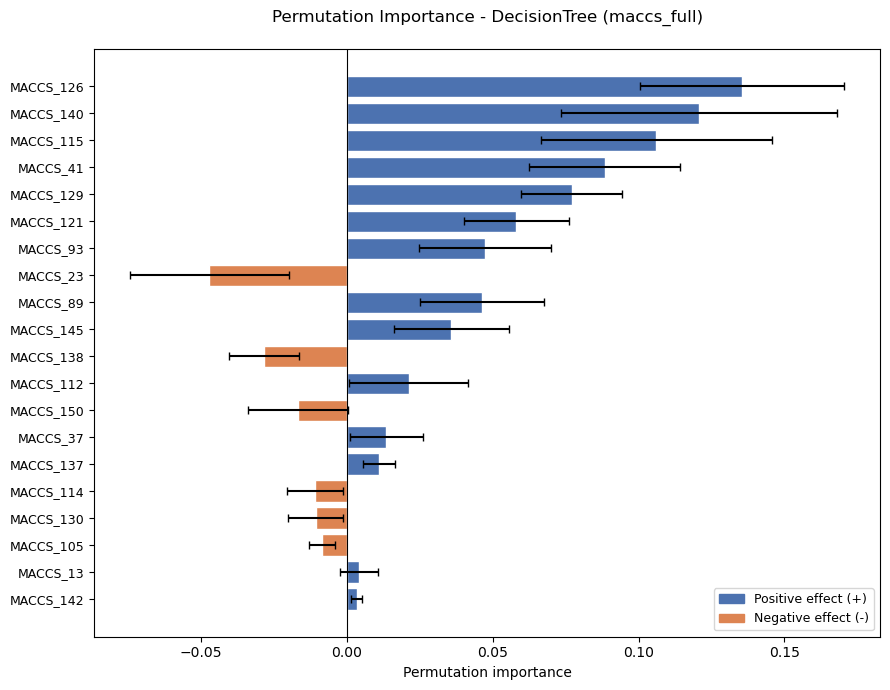

figuras/MACCs/paso9_permutation_importance_top3_DecisionTree_maccs.png guardado.

paraso9_permutation_importance_all.csv guardado con la importancia de los TOP 3 modelos.


In [18]:
# =============================================================================
# 8. Interpretabilidad: Permutation Feature Importance (TOP 3 modelos)
# =============================================================================
# La importancia por permutacion mide cuanto empeora el rendimiento del
# modelo (ROC-AUC) al barajar aleatoriamente los valores de un bit MACCS,
# rompiendo su relacion con la actividad. Se calcula sobre el TEST SET (no
# sobre train), para que refleje la contribucion real del bit a la capacidad
# de generalizacion, no a su ajuste a los datos de entrenamiento.
#
# La importancia por permutacion solo mide MAGNITUD (cuanto importa), no
# DIRECCION (si el bit favorece o penaliza la actividad). Para estimar la
# direccion se calcula la correlacion de Pearson entre el valor del bit (0/1)
# y la probabilidad predicha por el propio modelo en el test set: correlacion
# positiva -> la presencia de ese fragmento estructural aumenta la
# probabilidad de actividad; negativa -> la reduce. Es una aproximacion (no
# capta relaciones no monotonas), pero es el criterio habitual en QSAR cuando
# se usan modelos no lineales que no tienen coeficientes directos.
#
# En el grafico, la barra se dibuja hacia la DERECHA si el bit MACCS tiene
# efecto positivo sobre la actividad y hacia la IZQUIERDA si tiene efecto
# negativo (importancia con signo = importancia * signo de la correlacion).
#
# Se reutilizan los mismos TOP 3 modelos (top3) y el mismo feature set
# (fs_name / fs_cols) ya seleccionados en la seccion de Dominio de Aplicabilidad.

N_TOP_DESCRIPTORS = 20
N_REPEATS_PI       = 30

def permutation_importance_report(model_name, est, fs_name, feat_cols, X_te, y_te,
                                   n_repeats=N_REPEATS_PI, random_state=42):
    result = permutation_importance(
        est, X_te[feat_cols], y_te,
        scoring="roc_auc",
        n_repeats=n_repeats,
        random_state=random_state,
        n_jobs=-1,
    )

    if hasattr(est, "predict_proba"):
        y_prob = est.predict_proba(X_te[feat_cols])[:, 1]
    else:
        y_prob = est.decision_function(X_te[feat_cols])

    directions = []
    for col in feat_cols:
        col_vals = X_te[col].values
        if np.std(col_vals) == 0:
            directions.append(0.0)
        else:
            r, _ = pearsonr(col_vals, y_prob)
            directions.append(r)

    imp_df = pd.DataFrame({
        "descriptor"     : feat_cols,
        "importance_mean": result.importances_mean,
        "importance_std" : result.importances_std,
        "direction_corr" : directions,
    })
    imp_df["sign"] = np.where(imp_df["direction_corr"] >= 0, 1, -1)
    imp_df["signed_importance"] = imp_df["importance_mean"] * imp_df["sign"]
    imp_df["effect"] = np.where(imp_df["direction_corr"] >= 0, "positivo (+)", "negativo (-)")
    imp_df = imp_df.reindex(
        imp_df["importance_mean"].sort_values(ascending=False).index
    ).reset_index(drop=True)
    imp_df.insert(0, "model", model_name)
    imp_df.insert(1, "feature_set", fs_name)
    return imp_df


all_importance_dfs = []

for rank, row in top3.iterrows():
    rank += 1
    model_name = row["model"]
    key        = f"{model_name}__{fs_name}"
    est        = best_estimators[key]

    print("\n" + "=" * 60)
    print(f"[{rank}/3] Permutation importance: {model_name} | {fs_name} ({len(fs_cols)} bits MACCS)")
    print("=" * 60)

    imp_df = permutation_importance_report(model_name, est, fs_name, fs_cols, X_test_full, y_test)
    all_importance_dfs.append(imp_df)

    top_n = imp_df.head(N_TOP_DESCRIPTORS)
    out_csv = f'{OUTPUT_DIR_INT}/paso9_permutation_importance_top{rank}_{model_name}.csv'
    imp_df.to_csv(out_csv, index=False)
    print(f"Top {N_TOP_DESCRIPTORS} bits MACCS por importancia (ROC-AUC):")
    print(top_n[["descriptor", "importance_mean", "importance_std", "effect"]].to_string(index=False))
    print(f"{out_csv} guardado.")

    # Orden visual: de mayor a menor importancia absoluta, de arriba a abajo
    top_n_plot = top_n.iloc[::-1]
    colors = np.where(top_n_plot["sign"] > 0, "#4C72B0", "#DD8452")

    fig, ax = plt.subplots(figsize=(9, max(4, 0.35 * len(top_n_plot))))
    y_pos = np.arange(len(top_n_plot))
    ax.barh(y_pos, top_n_plot["signed_importance"],
            xerr=top_n_plot["importance_std"],
            color=colors, edgecolor="white", capsize=3)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(top_n_plot["descriptor"], fontsize=9)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel("Permutation importance")
    ax.set_title(f"Permutation Importance - {model_name} ({fs_name})\n")
    legend_patches = [
        plt.Rectangle((0, 0), 1, 1, color="#4C72B0", label="Positive effect (+)"),
        plt.Rectangle((0, 0), 1, 1, color="#DD8452", label="Negative effect (-)"),
    ]
    ax.legend(handles=legend_patches, loc="lower right", fontsize=9)
    plt.tight_layout()
    out_png = f'{FIGURAS}/paso9_permutation_importance_top{rank}_{model_name}_maccs.png'
    plt.savefig(out_png, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"{out_png} guardado.")

df_importance_all = pd.concat(all_importance_dfs, ignore_index=True)
df_importance_all.to_csv(f'{OUTPUT_DIR_INT}/paso9_permutation_importance_all.csv', index=False)
print(f"\nparaso9_permutation_importance_all.csv guardado con la importancia de los TOP 3 modelos.")


# 11.Guardado de los 3 mejores modelos como .joblib

In [19]:
import joblib
import os

ARTIFACTS_DIR = "modelos_joblib_maccs"
os.makedirs(ARTIFACTS_DIR, exist_ok=True)

LABEL_MEANING = {
    "1": "Activo (IC50 < 5 uM frente a Falcipaina-2)",
    "0": "Inactivo (IC50 >= 5 uM frente a Falcipaina-2)",
}

# --- Top 3 pipelines como DICCIONARIO nombre_modelo -> pipeline (no lista) ---
top3_pipelines = {
    row["model"]: best_estimators[f"{row['model']}__{fs_name}"]
    for _, row in top3.iterrows()
}

maccs_bundle = {
    "descriptor_type": "maccs",
    "feature_columns": fs_cols,
    "feature_medians": X_train_full[fs_cols].median(),
    "top3_models": top3_pipelines,
    "top3_ranking": top3.to_dict("records"),
    "ad_scaler": scaler_ad,
    "ad_nn": nn_ad,
    "ad_threshold": threshold,
    "ad_n_neighbors": 5,
    "background_sample": X_train_full[fs_cols].sample(
        min(100, len(X_train_full)), random_state=RANDOM_STATE),
    "label_meaning": LABEL_MEANING,
}

out_path = os.path.join(ARTIFACTS_DIR, "maccs_bundle.joblib")
joblib.dump(maccs_bundle, out_path)
print(f"Guardado: {out_path}")
print(f"Claves del bundle: {list(maccs_bundle.keys())}")

# Cada modelo se guarda junto con la lista de columnas (features) que espera
# a la entrada, para no tener que recordar despues en que orden/subset de
# columnas hay que pasarle los datos nuevos.
for key, est in best_estimators.items():
    model_name, fs_name = key.split("__")
    payload = {
        "pipeline": est,
        "feature_columns": feature_sets[fs_name],
        "model_name": model_name,
        "feature_set": fs_name,
    }
    joblib.dump(payload, os.path.join(ARTIFACTS_DIR, f"{key}.joblib"))

print(f"{len(best_estimators)} modelos guardados en '{ARTIFACTS_DIR}/'")

Guardado: modelos_joblib_maccs\maccs_bundle.joblib
Claves del bundle: ['descriptor_type', 'feature_columns', 'feature_medians', 'top3_models', 'top3_ranking', 'ad_scaler', 'ad_nn', 'ad_threshold', 'ad_n_neighbors', 'background_sample', 'label_meaning']
14 modelos guardados en 'modelos_joblib_maccs/'
